# TP3 · Big Data — Sentiment des avis Amazon avec Spark

**Question d’étude :** dans quelle mesure le titre et le texte d’un avis permettent-ils de retrouver sa polarité sur un corpus de quatre millions d’avis ?

**Cycle suivi :** Spark (Data → EDA → Prétraitement) → Transformation → ML → Évaluation → Déploiement.

| Étape | Question posée |
|---|---|
| [1. Data](#1-data--ingestion-spark) | Que contient le corpus et comment Spark le lit-il ? |
| [2. EDA](#2-eda--analyse-exploratoire-distribuée) | Comment les classes et la longueur des textes se répartissent-elles ? |
| [3. Prétraitement](#3-prétraitement--qualité-et-fuite-de-données) | Combien d’avis sont écartés et pourquoi ? |
| [4. Transformation](#4-transformation--du-texte-au-tf-idf) | Que devient un avis dans un vecteur creux ? |
| [5. ML](#5-ml--apprentissage-avec-spark-ml) | Comment comparer la régression logistique et Naïve Bayes ? |
| [6. Évaluation](#6-évaluation--test-officiel-nettoyé) | Quelles erreurs subsistent et comment le seuil les modifie-t-il ? |
| [7. Déploiement](#7-déploiement--prédiction-par-lot) | Comment réutiliser le modèle sur un nouveau CSV ? |

**Sources.** Les CSV d’[Amazon Polarity publiés sur Kaggle](https://www.kaggle.com/datasets/yacharki/amazon-reviews-for-sa-binary-negative-positive-csv/data) sont fournis dans le projet. Le [notebook de MuonNeutrino](https://www.kaggle.com/code/muonneutrino/sentiment-analysis-with-amazon-reviews) a servi de point de départ pour la tâche de classification. L’implémentation ci-dessous utilise Spark ML et traite les doublons avant l’évaluation.

## 0. Configuration

Installer l’environnement indiqué dans le [README du projet](../../README.md). En mode complet, quatre tâches peuvent s’exécuter en parallèle avec 6 Go de mémoire pour le pilote. Les réglages sont ajustables par variables d’environnement. Les graphes utilisent des agrégats et des échantillons limités, collectés après calcul dans Spark.

In [1]:
import csv
import json
import os
import sys
from collections import Counter
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
from pyspark import StorageLevel
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.classification import LogisticRegression, NaiveBayes
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import HashingTF, IDF, RegexTokenizer, SQLTransformer
from pyspark.ml.functions import vector_to_array
from pyspark.sql import SparkSession, functions as F
from IPython.display import Markdown, display
from pyspark.sql.types import IntegerType, StringType, StructField, StructType


os.environ["PYSPARK_PYTHON"] = sys.executable

def create_spark(name):
    master = os.environ.get("TP3_SPARK_MASTER")
    builder = SparkSession.builder.appName(name)
    if master:
        builder = builder.master(master)
    elif "SPARK_MASTER" not in os.environ and "PYSPARK_SUBMIT_ARGS" not in os.environ:
        builder = builder.master("local[4]")
    spark = (builder
             .config("spark.ui.showConsoleProgress", "false")
             .config("spark.driver.host", "127.0.0.1")
             .config("spark.driver.bindAddress", "127.0.0.1")
             .config("spark.driver.memory", os.environ.get("TP3_SPARK_MEMORY", "6g"))
             .config("spark.sql.shuffle.partitions", os.environ.get("TP3_SPARK_SHUFFLE", "32"))
             .getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
    return spark


def score_reviews(model, rows):
    missing = sorted({"title", "body"} - set(rows.columns))
    if missing:
        raise ValueError(f"Colonnes d'entrée absentes : {', '.join(missing)}")
    return model.transform(rows.select("title", "body")).select(
        "title", "body",
        F.when(F.col("prediction") == 1.0, "positif").otherwise("négatif").alias("sentiment"),
        vector_to_array("probability")[1].alias("score_positif"),
    )

fraction = float(os.environ.get("TP3_BIG_FRACTION", "1"))
assert 0 < fraction <= 1

TP = next((p for p in (Path.cwd(), Path.cwd() / "big", Path.cwd() / "TP3" / "big") if (p / "amazon_reviews_dataset").is_dir()), None)
if TP is None:
    raise FileNotFoundError("Ouvrir ce notebook depuis bigData/, TP3/ ou TP3/big/.")
ARTIFACTS = TP / ("artefacts" if fraction == 1 else "artefacts/rapide")
MODEL_NAME = "modele_sentiment_spark"

## 1. Data — Ingestion Spark

### 1.1 Corpus et contrat d’entrée

Le corpus distingue deux polarités, construites à partir des notes : **1 = négatif** (1–2 étoiles), **2 = positif** (4–5 étoiles). Les notes de 3 étoiles ont été écartées. Le texte est majoritairement en anglais. Le découpage officiel fournit 3,6 millions d’avis d’apprentissage et 400 000 avis de test. Il est conservé, puis audité pour limiter les répétitions entre les deux jeux.

### 1.2 Schéma explicite et fichiers compressés

`class_index` est lu comme entier. `review_title` et `review_text` deviennent `title` et `body` dans le notebook. Le schéma évite à Spark une passe d’inférence et l’option `FAILFAST` rend les erreurs de lecture visibles. Le nombre de fichiers et le nombre de partitions sont distincts : une partition correspond à une unité de lecture planifiée par Spark.

In [2]:
data = TP / "amazon_reviews_dataset"
train_csv = data / "train.csv"
test_csv = data / "test.csv"
paths = {
    "train": [train_csv] if train_csv.is_file() else sorted(data.glob("train-*.csv.gz")),
    "test": [test_csv] if test_csv.is_file() else [data / "test.csv.gz"],
}
if not all(files and all(path.is_file() for path in files) for files in paths.values()):
    raise FileNotFoundError("Jeux train ou test manquants dans amazon_reviews_dataset/.")

spark = create_spark("TP3 Amazon Polarity")
schema = StructType([
    StructField("class_index", IntegerType()),
    StructField("review_title", StringType()),
    StructField("review_text", StringType()),
])

def read_reviews(files):
    rows = (spark.read.schema(schema)
            .options(header=True, enforceSchema=False, quote='"', escape='"', mode="FAILFAST")
            .csv([path.resolve().as_uri() for path in files])
            .selectExpr("class_index", "review_title as title", "review_text as body"))
    return rows if fraction == 1 else rows.sample(False, fraction, seed=42)

raw = {split: read_reviews(files) for split, files in paths.items()}
print(f"Spark {spark.version} | {spark.sparkContext.master} | fraction analysée : {fraction:.1%}")
for split, files in paths.items():
    size_mb = sum(path.stat().st_size for path in files) / 1e6
    print(f"{split} : {len(files)} fichier(s), {size_mb:.1f} Mo sur disque, "
          f"{raw[split].rdd.getNumPartitions()} partitions de lecture")
raw["train"].printSchema()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/13 07:59:50 WARN Utils: Your hostname, LAPTOP-K2VAL7B9, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/13 07:59:50 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/13 07:59:51 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/11/13 07:59:52 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Spark 4.0.1 | local[4] | fraction analysée : 100.0%


train : 11 fichier(s), 618.2 Mo sur disque, 6 partitions de lecture
test : 1 fichier(s), 70.7 Mo sur disque, 1 partitions de lecture
root
 |-- class_index: integer (nullable = true)
 |-- title: string (nullable = true)
 |-- body: string (nullable = true)



### 1.3 Aperçu des avis

Les exemples proviennent du corpus d’apprentissage. Les extraits sont tronqués pour la lecture, sans tronquer les données utilisées par le modèle.

In [3]:
preview = raw["train"].select(
    F.when(F.col("class_index") == 1, "Négatif").otherwise("Positif").alias("polarité"),
    F.substring("title", 1, 40).alias("titre"),
    F.substring("body", 1, 100).alias("extrait"),
)
preview.show(5, truncate=False)

+--------+--------------------------------------+----------------------------------------------------------------------------------------------------+
|polarité|titre                                 |extrait                                                                                             |
+--------+--------------------------------------+----------------------------------------------------------------------------------------------------+
|Positif |What you would hear in hell!          |This is my first Slayer dvd stage purchase the price is great for the performance kick your butt sho|
|Positif |This rocks!                           |Fabulous DVD. Nice to know they haven't lost the touch that a lot of the metal bands that have been |
|Positif |Slayer really are Still Reigning      |Slayer having taken their "breakout" album Reign in Blood, recorded the entire performance live last|
|Positif |LOVE IT !!                            |I totally love this DVD. I'm not a die hard S

## 2. EDA — Analyse exploratoire distribuée

### 2.1 Équilibre des classes et champs vides

L’exploration porte sur l’apprentissage. Un titre vide ne suffit pas à écarter un avis dont le corps est exploitable. Les indicateurs de qualité sont calculés à partir des données brutes, avant le nettoyage. Les classes sont comparées en effectifs et en part du corpus.

In [4]:
start = perf_counter()
profile = raw["train"].select(
    "class_index", F.length(F.coalesce("body", F.lit(""))).alias("length"),
    (F.length(F.trim(F.coalesce("title", F.lit("")))) == 0).cast("int").alias("title_vide"),
).withColumn("tranche",
    F.when(F.col("length") == 0, 0)
    .when(F.col("length") < 100, 1).when(F.col("length") < 300, 2)
    .when(F.col("length") < 600, 3).otherwise(4),
).groupBy("class_index", "tranche").agg(F.count("*").alias("n"), F.sum("title_vide").alias("titles")).collect()
print(f"Agrégation Spark : {perf_counter() - start:.1f} s")
class_names = ["Négatif", "Positif"]
counts = [sum(r.n for r in profile if r.class_index == i) for i in [1, 2]]
print("Titres vides :", sum(r.titles for r in profile))
print("Textes absents ou vides :", sum(r.n for r in profile if r.tranche == 0))
print("Classes invalides :", sum(r.n for r in profile if r.class_index not in [1, 2]))


n_train_raw = sum(r.n for r in profile)
if fraction == 1:
    assert counts == [1_800_000, 1_800_000]
for label, n in zip(class_names, counts):
    print(f"{label} : {n:,} avis ({n / n_train_raw:.2%})")

Agrégation Spark : 17.2 s
Titres vides : 77
Textes absents ou vides : 0
Classes invalides : 0
Négatif : 1,800,000 avis (50.00%)
Positif : 1,800,000 avis (50.00%)


### 2.2 Distribution des longueurs

Le graphique par tranche montre les longueurs fréquentes et celles qui concernent moins d’avis. Des avis très courts offrent peu d’indices au modèle. Les avis longs peuvent contenir des éléments contradictoires, comme un produit jugé bon malgré un défaut.

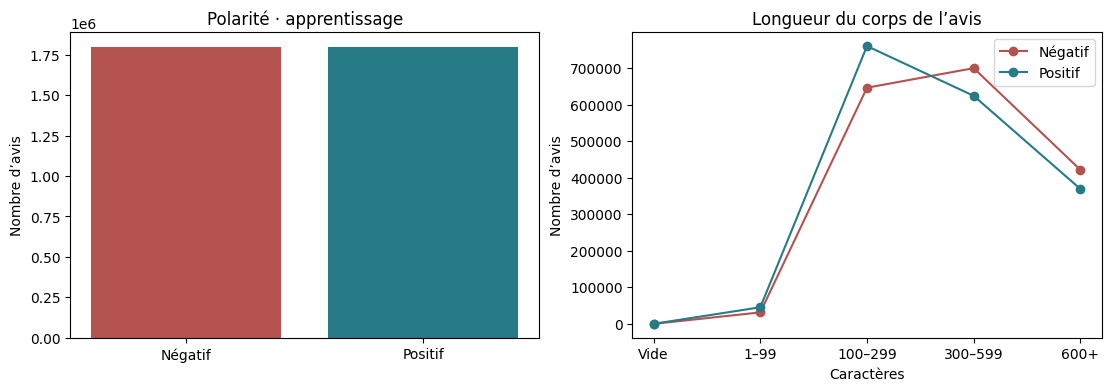

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axes[0].bar(class_names, counts, color=["#B45250", "#267B87"])
axes[0].set(title="Polarité · apprentissage", ylabel="Nombre d’avis")
bins = ["Vide", "1–99", "100–299", "300–599", "600+"]
for label, color, name in zip([1, 2], ["#B45250", "#267B87"], class_names):
    bins_n = {r.tranche: r.n for r in profile if r.class_index == label}
    axes[1].plot(bins, [bins_n.get(i, 0) for i in range(5)], marker="o", color=color, label=name)
axes[1].set(title="Longueur du corps de l’avis", xlabel="Caractères", ylabel="Nombre d’avis")
axes[1].legend()
ARTIFACTS.mkdir(parents=True, exist_ok=True)
fig.savefig(ARTIFACTS / "eda.png", dpi=120)
plt.show()

### 2.3 Comparer les quantiles plutôt que les seuls extrêmes

La médiane décrit un avis typique. L’intervalle du 25ᵉ au 75ᵉ centile contient environ la moitié des avis, et le 90ᵉ centile donne un repère pour les textes longs. `percentile_approx` estime ces repères dans Spark en évitant de transférer les longueurs individuelles vers Python.

Négatif : P25=227, P50=378, P75=583, P90=777 caractères
Positif : P25=190, P50=333, P75=547, P90=757 caractères


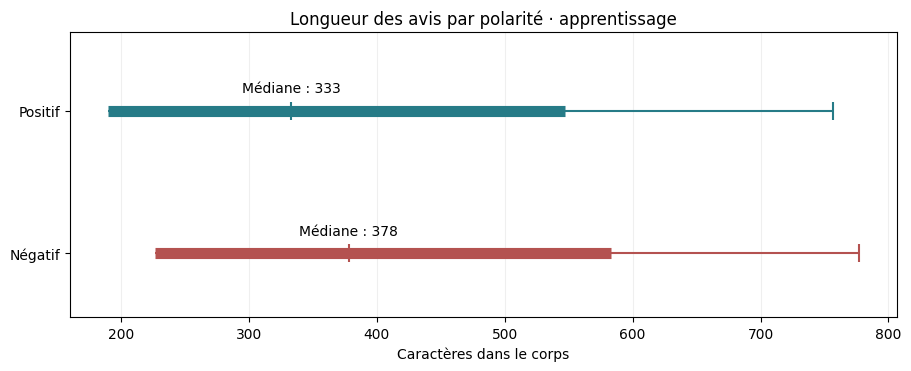

In [6]:
quantiles = (raw["train"].where(F.col("class_index").isin(1, 2))
    .groupBy("class_index")
    .agg(F.percentile_approx(F.length(F.coalesce("body", F.lit(""))),
                             [0.25, 0.50, 0.75, 0.90], 10000).alias("longueurs"))
    .orderBy("class_index").collect())
fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
for i, row in enumerate(quantiles):
    q25, q50, q75, q90 = row.longueurs
    color = ["#B45250", "#267B87"][row.class_index - 1]
    ax.hlines(i, q25, q90, color=color, linewidth=1.5)
    ax.hlines(i, q25, q75, color=color, linewidth=8)
    ax.scatter([q50, q90], [i, i], color=color, marker="|", s=180)
    ax.annotate(f"Médiane : {q50}", (q50, i), xytext=(0, 13),
                textcoords="offset points", ha="center")
    print(f"{class_names[row.class_index - 1]} : P25={q25}, P50={q50}, P75={q75}, P90={q90} caractères")
ax.set(yticks=list(range(len(quantiles))), yticklabels=[class_names[r.class_index-1] for r in quantiles],
       ylim=(-0.45, len(quantiles)-0.45), xlabel="Caractères dans le corps",
       title="Longueur des avis par polarité · apprentissage")
ax.grid(axis="x", alpha=0.2)
plt.show()

**Lecture des deux graphiques.** L’équilibre des classes est une propriété de la construction du corpus. Il ne représente pas forcément les proportions d’avis positifs et négatifs sur Amazon. La longueur aide à comprendre les erreurs par segment, mais le modèle n’utilise pas la longueur comme variable dédiée.

## 3. Prétraitement — Qualité et fuite de données

### 3.1 Normalisation et détection des doublons

Spark concatène le titre et le corps, passe en minuscules et normalise les espaces. On garde les avis ayant une étiquette valide et au moins une lettre ou un chiffre. Un SHA-256 identifie un texte normalisé. Les répétitions de même polarité deviennent un seul avis. Si un groupe contient des étiquettes différentes, il est écarté intégralement. La colonne `copies` sert à compter les lignes à chaque étape.

In [7]:
normalize = SQLTransformer(statement=r"""
    SELECT *, trim(regexp_replace(
        regexp_replace(lower(concat_ws(' ', title, body)), r'\\[nr]', ' '),
        r'\s+', ' '
    )) AS text FROM __THIS__
""")

def collapse(rows):
    valid = (normalize.transform(rows)
             .where(F.col("class_index").isin(1, 2) & F.col("text").rlike(r"[\p{L}\p{N}]"))
             .withColumn("key", F.sha2("text", 256)))
    grouped = valid.groupBy("key").agg(
        F.count("*").alias("copies"),
        F.min("class_index").alias("low"),
        F.max("class_index").alias("high"),
        F.min(F.struct("title", "body")).alias("review"),
    )
    return grouped

### 3.2 Exclure du test les textes déjà vus

Une jointure `left_anti` conserve les avis de test dont l’empreinte est absente de l’apprentissage brut valide, y compris les groupes ambigus écartés de l’apprentissage. Si le même texte était conservé dans les deux jeux, un score élevé pourrait refléter sa mémorisation. Les quasi-doublons et les reformulations restent une limite.

In [8]:
groups = {split: collapse(frame).persist(StorageLevel.DISK_ONLY) for split, frame in raw.items()}
def consistent(group):
    return group.where(F.col("low") == F.col("high")).select(
        "key", "review.*", (F.col("low") - 1).cast("double").alias("label"),
    )

train = consistent(groups["train"]).persist(StorageLevel.DISK_ONLY)
test = (consistent(groups["test"])
    .join(groups["train"].select("key"), "key", "left_anti")
    .persist(StorageLevel.DISK_ONLY))
train_counts = {int(r.label): r["count"] for r in train.groupBy("label").count().collect()}
test_counts = {int(r.label): r["count"] for r in test.groupBy("label").count().collect()}
assert set(train_counts) == set(test_counts) == {0, 1}
print("Partitions après nettoyage :", train.rdd.getNumPartitions(), test.rdd.getNumPartitions())

Partitions après nettoyage : 32 32


### 3.3 Bilan chiffré du nettoyage

Le bilan ventile les retraits dans quatre catégories disjointes. « Répétitions » compte les lignes en plus dans les groupes à polarité cohérente. « Labels contradictoires » compte toutes les lignes des groupes ambigus. « Déjà vu » compte les représentants du test retirés après dédoublonnage.

In [9]:
raw_counts = {"train": n_train_raw, "test": raw["test"].count()}
if fraction == 1:
    assert raw_counts == {"train": 3_600_000, "test": 400_000}
audit = {}
for split, group in groups.items():
    same_label = F.col("low") == F.col("high")
    summary = group.agg(
        F.sum("copies").alias("valides"),
        F.sum(F.when(same_label, F.col("copies") - 1).otherwise(0)).alias("répétitions"),
        F.sum(F.when(~same_label, F.col("copies")).otherwise(0)).alias("contradictoires"),
        F.sum(same_label.cast("long")).alias("cohérents"),
    ).first().asDict()
    kept = sum((train_counts if split == "train" else test_counts).values())
    losses = {
        "Texte ou étiquette invalide": raw_counts[split] - summary["valides"],
        "Répétitions": summary["répétitions"],
        "Labels contradictoires": summary["contradictoires"],
        "Déjà vu en apprentissage": summary["cohérents"] - kept,
    }
    assert min(losses.values()) >= 0 and raw_counts[split] == kept + sum(losses.values())
    audit[split] = {"brut": raw_counts[split], **losses, "retenus": kept}
assert audit["train"]["Déjà vu en apprentissage"] == 0
for group in groups.values():
    group.unpersist()

table = ["| Étape | Apprentissage | Test |", "|---|---:|---:|"]
for item in audit["train"]:
    table.append(f"| {item.capitalize()} | {audit['train'][item]:,} | {audit['test'][item]:,} |")
display(Markdown("\n".join(table)))

| Étape | Apprentissage | Test |
|---|---:|---:|
| Brut | 3,600,000 | 400,000 |
| Texte ou étiquette invalide | 2 | 0 |
| Répétitions | 337 | 4 |
| Labels contradictoires | 2 | 0 |
| Déjà vu en apprentissage | 0 | 82 |
| Retenus | 3,599,659 | 399,914 |

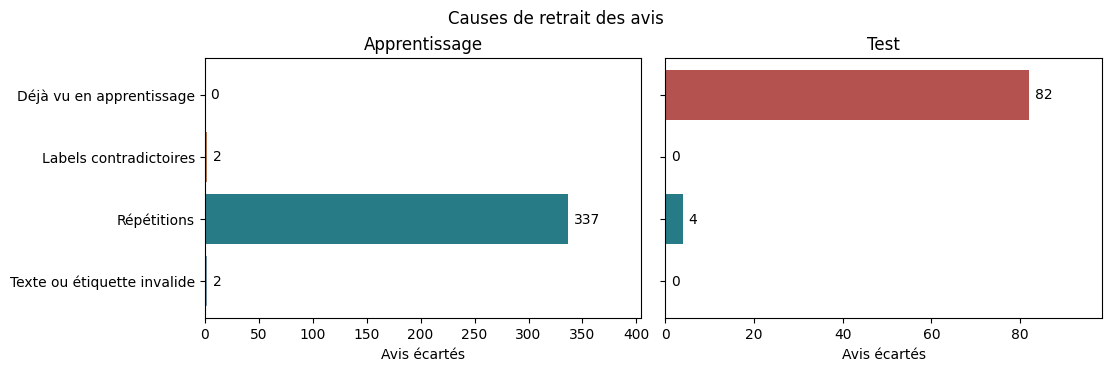

In [10]:
loss_labels = list(audit["train"])[1:-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained", sharey=True)
for ax, (split, label) in zip(axes, [("train", "Apprentissage"), ("test", "Test")]):
    values = [audit[split][cause] for cause in loss_labels]
    ax.barh(loss_labels, values, color=["#7896A7", "#267B87", "#BD7853", "#B45250"])
    ax.set(title=label, xlabel="Avis écartés")
    ax.margins(x=0.2)
    for i, value in enumerate(values):
        ax.annotate(f"{value:,}", (value, i), xytext=(4, 0), textcoords="offset points", va="center")
fig.suptitle("Causes de retrait des avis")
plt.show()

**Coût de la préparation.** Les agrégations par empreinte et la jointure redistribuent des lignes entre partitions. C’est le *shuffle*. Les DataFrames nettoyés sont persistés sur disque car ils sont lus plusieurs fois. Cette décision réduit les recalculs et évite de garder plusieurs millions de textes en mémoire.

## 4. Transformation — Du texte au TF-IDF

### 4.1 Chaîne de transformation

1. Le texte normalisé passe dans `RegexTokenizer`. Il garde les lettres, les chiffres et les apostrophes, ce qui préserve des formes comme `don't`.
2. `HashingTF` associe chaque terme à un des 65 536 indices et compte les occurrences. Le résultat est creux : seules les positions actives sont stockées. Des collisions d’indices restent possibles.
3. `IDF` réduit le poids des indices présents dans de nombreux avis. `minDocFreq=2` donne un poids nul aux indices observés dans un seul document. Les poids sont ajustés sur l’apprentissage seulement.

In [11]:
stages = [
    normalize,
    RegexTokenizer(inputCol="text", outputCol="tokens", pattern=r"[^\p{L}\p{N}']+", minTokenLength=1),
    HashingTF(inputCol="tokens", outputCol="tf", numFeatures=2**16),
    IDF(inputCol="tf", outputCol="features", minDocFreq=2),
]
print(" → ".join(type(stage).__name__ for stage in stages))
feature_model = Pipeline(stages=stages).fit(train)

SQLTransformer → RegexTokenizer → HashingTF → IDF


### 4.2 Suivre de vrais avis dans le pipeline

Sur trois avis d’apprentissage, on affiche quelques tokens puis la dimension et le nombre de composantes non nulles. Le nombre de positions actives peut être inférieur au nombre de tokens à cause des répétitions, des collisions et des poids IDF nuls.

In [12]:
demo = feature_model.transform(train.orderBy("key").limit(3))
for row in demo.select("title", "tokens", "features").collect():
    print(f"{(row.title or '(sans titre)')[:70]}")
    print(f"  Tokens ({len(row.tokens)}) : {', '.join(row.tokens[:14])}")
    print(f"  TF-IDF : {row.features.numNonzeros()} composantes non nulles sur {row.features.size:,}")

Bounce!! Good Old school Music!!!
  Tokens (56) : bounce, good, old, school, music, the, bounce, music, from, down, south, was, the, best
  TF-IDF : 45 composantes non nulles sur 65,536
HP LJ4600 Quality issues with cartridges and support
  Tokens (93) : hp, lj4600, quality, issues, with, cartridges, and, support, now, we, have, this, printer, for
  TF-IDF : 65 composantes non nulles sur 65,536
Just bad
  Tokens (27) : just, bad, this, series, was, just, not, very, good, the, art, is, overboard, over
  TF-IDF : 23 composantes non nulles sur 65,536


## 5. ML — Apprentissage avec Spark ML

### 5.1 Protocole commun

Les deux modèles voient les mêmes avis d’apprentissage et les mêmes vecteurs TF-IDF. La **régression logistique** ajuste une frontière linéaire avec régularisation. **Naïve Bayes multinomial** fournit un point de comparaison rapide sur des caractéristiques non négatives et suppose une indépendance conditionnelle des indices, approximation courante en classification de texte.

La **classe majoritaire** sert de référence sans texte. En cas d’égalité, on choisit le label négatif. Les réglages sont fixés avant l’évaluation. La régression logistique est désignée à l’avance pour la démonstration de déploiement.

In [13]:
majority = max(train_counts, key=lambda label: (train_counts[label], -label))
features_train = feature_model.transform(train).select("label", "features").persist(StorageLevel.DISK_ONLY)
models = {}
timings = {}
estimators = {
    "logistique": LogisticRegression(maxIter=35, regParam=0.01, elasticNetParam=0.0),
    "naive_bayes": NaiveBayes(modelType="multinomial", smoothing=1.0),
}
for name, estimator in estimators.items():
    started = perf_counter()
    models[name] = estimator.fit(features_train)
    timings[name] = perf_counter() - started
    print(f"{name} : {timings[name]:.1f} s")
features_train.unpersist()
model = PipelineModel(stages=[*feature_model.stages, models["logistique"]])
print("Classe de référence :", class_names[majority])

logistique : 151.8 s


naive_bayes : 12.5 s
Classe de référence : Positif


Le premier chronométrage inclut le calcul et la mise en cache des vecteurs. Le second profite de ce cache. Les temps décrivent l’exécution du notebook et ne constituent pas un benchmark équitable entre les algorithmes.

### 5.2 Vérifier la convergence

La fonction objectif de la régression logistique combine l’erreur du modèle et sa pénalité de régularisation. La courbe décrit l’optimisation sur l’apprentissage. Elle ne mesure pas la performance sur des avis nouveaux.

Valeur initiale : 0.6931 | finale : 0.2569


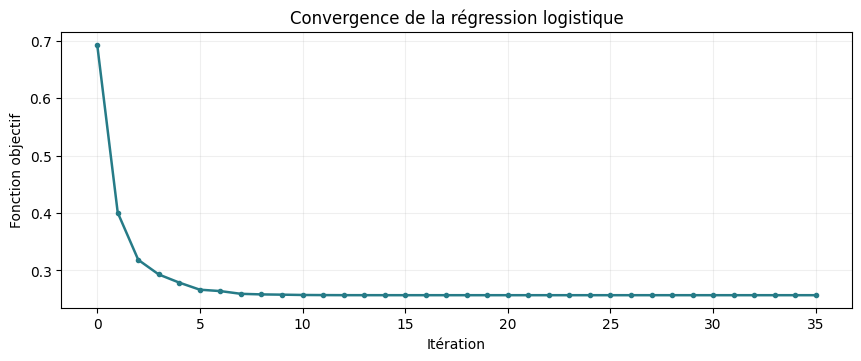

In [14]:
objective = models["logistique"].summary.objectiveHistory
print(f"Valeur initiale : {objective[0]:.4f} | finale : {objective[-1]:.4f}")
fig, ax = plt.subplots(figsize=(8.5, 3.5), layout="constrained")
ax.plot(range(len(objective)), objective, color="#267B87", marker=".", linewidth=1.8)
ax.set(xlabel="Itération", ylabel="Fonction objectif", title="Convergence de la régression logistique")
ax.grid(alpha=0.2)
plt.show()

## 6. Évaluation — Test officiel nettoyé

### 6.1 Métriques communes

L’accuracy est la proportion de bonnes prédictions. La précision d’une classe indique la part des prédictions de cette classe qui sont correctes, et le rappel la part des avis réels de cette classe qui sont retrouvés. Le F1 macro donne le même poids aux deux classes. L’AUC ROC et l’AUC PR comparent le classement obtenu en faisant varier le seuil. La classe positive est le label 1.

In [15]:
def divide(a, b):
    return a / b if b else 0.0

def confusion(scored_rows):
    cm = [[0, 0], [0, 0]]
    for row in scored_rows.groupBy("label", "prediction").count().collect():
        cm[int(row.label)][int(row.prediction)] = row["count"]
    return cm

def summarize(cm):
    precision = [divide(cm[i][i], cm[0][i] + cm[1][i]) for i in range(2)]
    recall = [divide(cm[i][i], sum(cm[i])) for i in range(2)]
    f1 = [divide(2 * p * r, p + r) for p, r in zip(precision, recall)]
    return {"accuracy": divide(cm[0][0] + cm[1][1], sum(map(sum, cm))),
            "precision": precision, "rappel": recall, "f1_macro": sum(f1) / 2}

n_by_class = [test_counts[0], test_counts[1]]
baseline = [[n if col == majority else 0 for col in range(2)] for n in n_by_class]
results = {"majoritaire": summarize(baseline)}
features_test = feature_model.transform(test).select("label", F.length("text").alias("length"), "features")
features_test = features_test.persist(StorageLevel.DISK_ONLY)
matrices = {}
for name, estimator in models.items():
    predictions = (estimator.transform(features_test)
        .select("label", "prediction", "rawPrediction", "length", vector_to_array("probability")[1].alias("score"))
        .persist(StorageLevel.DISK_ONLY))
    matrices[name] = confusion(predictions)
    assert [sum(row) for row in matrices[name]] == n_by_class
    results[name] = summarize(matrices[name])
    results[name].update({
        key: BinaryClassificationEvaluator(rawPredictionCol="score", metricName=metric).evaluate(predictions)
        for key, metric in [("auc_roc", "areaUnderROC"), ("auc_pr", "areaUnderPR")]
    })
    if name == "logistique":
        scored = predictions
    else:
        predictions.unpersist()
features_test.unpersist()
matrix = matrices["logistique"]

In [16]:
names = {"majoritaire": "Classe majoritaire", "logistique": "Régression logistique", "naive_bayes": "Naïve Bayes"}
table = ["| Modèle | Accuracy | F1 macro | AUC ROC | AUC PR |", "|---|---:|---:|---:|---:|"]
for name, result in results.items():
    roc = f"{result['auc_roc']:.4f}" if "auc_roc" in result else "—"
    pr = f"{result['auc_pr']:.4f}" if "auc_pr" in result else "—"
    table.append(f"| {names[name]} | {result['accuracy']:.2%} | {result['f1_macro']:.4f} | {roc} | {pr} |")
display(Markdown("\n".join(table)))
gap = 100 * (results["logistique"]["accuracy"] - results["majoritaire"]["accuracy"])
display(Markdown(f"La régression logistique gagne **{gap:.2f} points d’accuracy** sur la référence majoritaire."))

| Modèle | Accuracy | F1 macro | AUC ROC | AUC PR |
|---|---:|---:|---:|---:|
| Classe majoritaire | 50.01% | 0.3334 | — | — |
| Régression logistique | 90.49% | 0.9049 | 0.9626 | 0.9611 |
| Naïve Bayes | 82.85% | 0.8284 | 0.8950 | 0.8738 |

La régression logistique gagne **40.48 points d’accuracy** sur la référence majoritaire.

### 6.2 Matrice de confusion et résultats par classe

La ligne indique la classe réelle, la colonne la classe prédite. Les cases hors diagonale séparent les avis négatifs pris pour des positifs des avis positifs classés négatifs. Les deux types d’erreur peuvent avoir des coûts différents selon l’usage.

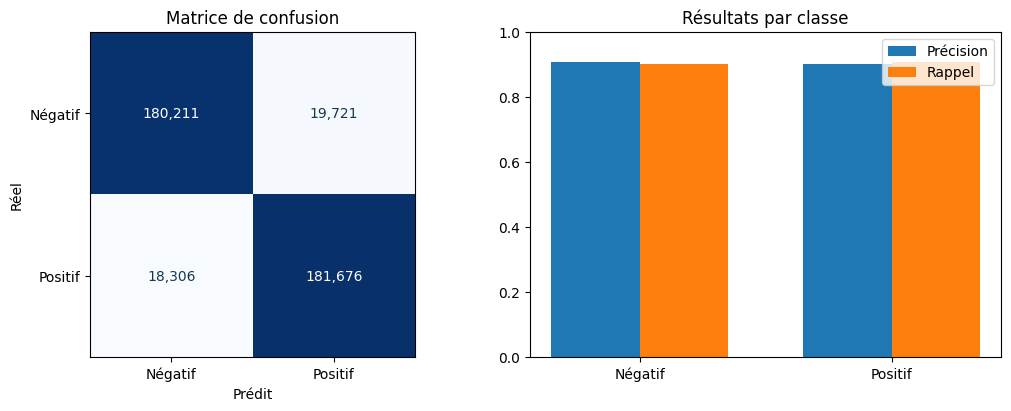

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].imshow(matrix, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, f"{matrix[i][j]:,}", ha="center", va="center",
                     color="white" if matrix[i][j] > max(map(max, matrix)) / 2 else "#15384b")
axes[0].set(xticks=[0, 1], yticks=[0, 1], xticklabels=class_names, yticklabels=class_names,
            xlabel="Prédit", ylabel="Réel", title="Matrice de confusion")
width = 0.35
for j, (key, title) in enumerate([("precision", "Précision"), ("rappel", "Rappel")]):
    axes[1].bar([i + (j - 0.5) * width for i in range(2)], results["logistique"][key], width, label=title)
axes[1].set(xticks=[0, 1], xticklabels=class_names, ylim=(0, 1), title="Résultats par classe")
axes[1].legend()
ARTIFACTS.mkdir(parents=True, exist_ok=True)
fig.savefig(ARTIFACTS / "evaluation.png", dpi=120)
plt.show()

### 6.3 Effet du seuil et courbes ROC / précision-rappel

Le score positif peut servir à classer les avis. Augmenter le seuil réduit généralement le nombre d’avis retenus comme positifs. Le rappel peut alors baisser et la précision monter. Spark agrège les scores en 100 tranches. Les courbes ci-dessous sont des approximations à partir de ces tranches. Les AUC du tableau proviennent de l’évaluateur Spark.

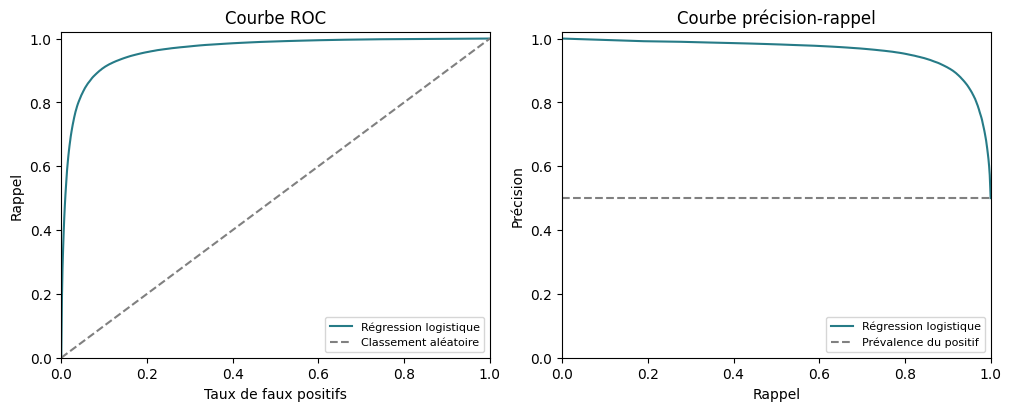

Seuil     Précision   Rappel      Taux de faux positifs
 0.25        81.12%    96.36%       22.43%
 0.50        90.21%    90.85%        9.86%
 0.75        95.54%    78.75%        3.68%


In [18]:
bucket_count = 100
bucketed = (scored.withColumn("bucket", F.least(F.lit(bucket_count - 1),
        F.floor(F.col("score") * bucket_count).cast("int")))
    .groupBy("bucket", "label").count().collect())
score_hist = [[0] * bucket_count for _ in range(2)]
for row in bucketed:
    score_hist[int(row.label)][row.bucket] = row["count"]
assert [sum(hist) for hist in score_hist] == n_by_class

tpr, fpr, precision = [0.0], [0.0], [1.0]
tp = fp = 0
for bucket in reversed(range(bucket_count)):
    fp += score_hist[0][bucket]
    tp += score_hist[1][bucket]
    tpr.append(tp / n_by_class[1])
    fpr.append(fp / n_by_class[0])
    precision.append(tp / (tp + fp) if tp + fp else 1.0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].plot(fpr, tpr, color="#267B87", label="Régression logistique")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Classement aléatoire")
axes[0].set(xlabel="Taux de faux positifs", ylabel="Rappel", title="Courbe ROC")
axes[1].plot(tpr, precision, color="#267B87", label="Régression logistique")
axes[1].axhline(n_by_class[1] / sum(n_by_class), linestyle="--", color="gray", label="Prévalence du positif")
axes[1].set(xlabel="Rappel", ylabel="Précision", title="Courbe précision-rappel")
for ax in axes:
    ax.set(xlim=(0, 1), ylim=(0, 1.02))
    ax.legend(loc="lower right", fontsize=8)
plt.show()

print("Seuil     Précision   Rappel      Taux de faux positifs")
for cutoff in [25, 50, 75]:
    i = bucket_count - cutoff
    print(f"{cutoff / bucket_count:>5.2f}     {precision[i]:>9.2%}   {tpr[i]:>7.2%}     {fpr[i]:>8.2%}")

Ce tableau illustre plusieurs seuils sur le test. Pour décider d’un seuil en production, il faudrait un jeu de validation distinct et une règle métier fixée à l’avance, par exemple un rappel minimal.

### 6.4 Scores par classe réelle

Deux distributions bien séparées indiquent que le score distingue les deux groupes. Leur zone de recouvrement montre où se concentrent les décisions difficiles. Un score élevé représente une sortie du modèle. Une étude de calibration séparée serait nécessaire pour l’interpréter comme une fréquence fiable.

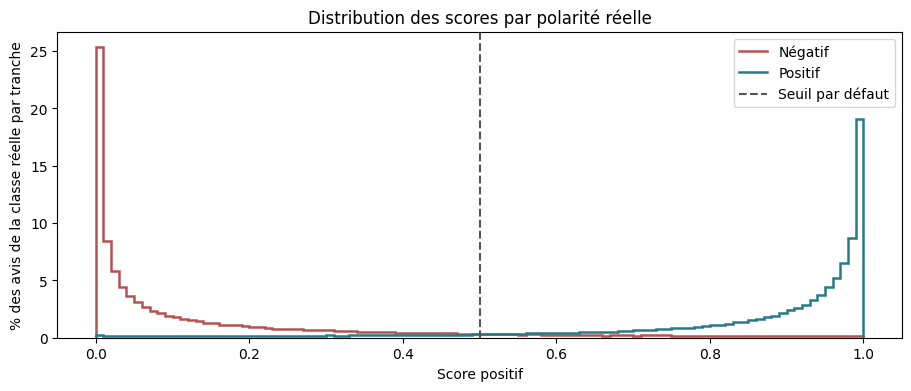

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
edges = [i / bucket_count for i in range(bucket_count + 1)]
for i, color in enumerate(["#B45250", "#267B87"]):
    ax.stairs([100 * count / n_by_class[i] for count in score_hist[i]], edges,
              color=color, linewidth=1.8, label=class_names[i])
ax.axvline(0.5, color="#555555", linestyle="--", label="Seuil par défaut")
ax.set(xlabel="Score positif", ylabel="% des avis de la classe réelle par tranche",
       title="Distribution des scores par polarité réelle")
ax.legend()
plt.show()

### 6.5 Les erreurs varient-elles avec la longueur ?

La performance moyenne masque les écarts entre groupes d’avis. On calcule ici le taux d’erreur par longueur de texte normalisé, en indiquant le nombre d’avis de chaque groupe. Cette comparaison est descriptive. La composition et le contenu des groupes peuvent aussi expliquer les écarts.

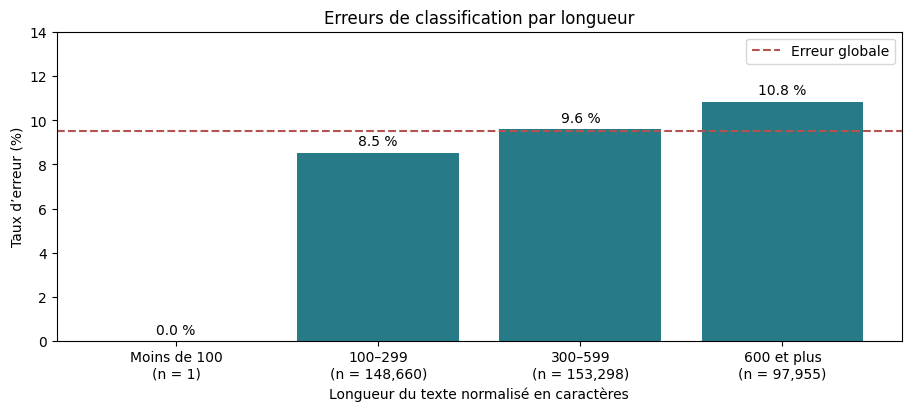

In [20]:
length_bins = ["Moins de 100", "100–299", "300–599", "600 et plus"]
by_length = (scored.withColumn("segment",
        F.when(F.col("length") < 100, 0).when(F.col("length") < 300, 1)
         .when(F.col("length") < 600, 2).otherwise(3))
    .groupBy("segment")
    .agg(F.count("*").alias("n"), F.sum((F.col("label") != F.col("prediction")).cast("int")).alias("errors"))
    .orderBy("segment").collect())
assert sum(row.n for row in by_length) == sum(n_by_class)
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
labels = [f"{length_bins[row.segment]}\n(n = {row.n:,})" for row in by_length]
rates = [100 * row.errors / row.n for row in by_length]
bars = ax.bar(labels, rates, color="#267B87")
ax.bar_label(bars, labels=[f"{rate:.1f} %" for rate in rates], padding=3)
ax.axhline(100 * (1 - results["logistique"]["accuracy"]), color="#B45250",
           linestyle="--", label="Erreur globale")
ax.set(xlabel="Longueur du texte normalisé en caractères", ylabel="Taux d’erreur (%)",
       ylim=(0, max(rates) * 1.2 + 1), title="Erreurs de classification par longueur")
ax.legend()
plt.show()

## 7. Déploiement — Prédiction par lot

### 7.1 Sauvegarder la chaîne complète

Le modèle livré inclut la normalisation, la tokenisation, les poids IDF appris et le classifieur. On le recharge depuis le disque et on vérifie que les sorties sont identiques sur trois vrais avis de test fournis sans étiquette. Cet exemple valide l’export et le rechargement. L’évaluation de la qualité repose sur les métriques de la section 6.

In [21]:
out = ARTIFACTS
out.mkdir(parents=True, exist_ok=True)
model_uri = (out / MODEL_NAME).resolve().as_uri()
model.write().overwrite().save(model_uri)
reloaded = PipelineModel.load(model_uri)

example = [(row.title, row.body) for row in test.where(
    F.col("title").isNotNull() & F.col("body").isNotNull()
).orderBy("key").select("title", "body").take(3)]
assert len(example) == 3
with (out / "exemple_entree.csv").open("w", encoding="utf-8", newline="") as handle:
    writer = csv.writer(handle)
    writer.writerow(["title", "body"])
    writer.writerows(example)
example_df = spark.read.options(header=True, multiLine=True, quote='"', escape='"').csv((out / "exemple_entree.csv").resolve().as_uri())
before = score_reviews(model, example_df).orderBy("title").collect()
after = score_reviews(reloaded, example_df).orderBy("title").collect()
assert before == after and len(after) == len(example)
for row in after:
    print(f"{row.title} → {row.sentiment} (score positif = {row.score_positif:.3f})")

report = {"fraction": fraction, "n_train": sum(train_counts.values()), "n_test": sum(n_by_class),
          "secondes_fit": timings["logistique"], "durees_classifieurs": timings,
          "matrice": matrix, "modeles": results, "audit_nettoyage": audit}
(out / "metriques_test.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
config = {
    "modele": "Régression logistique",
    "dossier_modele": MODEL_NAME,
    "colonnes_entree": ["title", "body"],
    "classe_positive": 1,
    "fraction_donnees": fraction,
    "fichier_metriques": "metriques_test.json",
}
(out / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")

for frame in [train, test, scored]:
    frame.unpersist()

Bandido? → négatif (score positif = 0.460)
Purchased before. → négatif (score positif = 0.431)
worst vacuum ever → négatif (score positif = 0.049)


### 7.2 Réutiliser le modèle sur un CSV

Pour lancer uniquement la prédiction, exécuter la cellule **Configuration**, puis celle ci-dessous. Le CSV d’entrée doit avoir les colonnes `title` et `body`. La sortie ajoute la classe prédite et le score positif. Spark écrit le résultat sous forme d’un dossier CSV, avec un fichier par partition de sortie. Le répertoire de prédictions est remplacé à chaque exécution.

In [22]:
model_dir = ARTIFACTS
input_csv = model_dir / "exemple_entree.csv"
output_dir = model_dir / "predictions"

if input_csv.resolve().is_relative_to(output_dir.resolve()):
    raise ValueError("Le CSV d'entree ne doit pas se trouver dans le dossier de sortie.")

spark = create_spark("TP3 Prédiction Amazon")
try:
    model_lot = PipelineModel.load((model_dir / MODEL_NAME).resolve().as_uri())
    avis = (spark.read.options(header=True, mode="FAILFAST", multiLine=True, quote='"', escape='"')
           .csv(input_csv.resolve().as_uri()))
    predictions = score_reviews(model_lot, avis)
    predictions.write.mode("overwrite").option("header", True).csv(output_dir.resolve().as_uri())
    predictions.select("title", "sentiment", "score_positif").show(5, truncate=False)
finally:
    spark.stop()

+-----------------+---------+-------------------+
|title            |sentiment|score_positif      |
+-----------------+---------+-------------------+
|Purchased before.|négatif  |0.4306180552665486 |
|worst vacuum ever|négatif  |0.04945899165142065|
|Bandido?         |négatif  |0.45958490972223853|
+-----------------+---------+-------------------+



## 8. Bilan et limites

Le cycle complet relie les fichiers originaux à un modèle réutilisable. Les résultats ci-dessus portent sur le test officiel après contrôle des étiquettes et retrait des doublons exacts. Les graphes de longueur et de score aident à comprendre les limites du chiffre moyen.

- **Données.** Les avis neutres sont absents. La proportion de positifs a été fixée lors de la constitution du corpus.
- **Généralisation.** Le test ne vérifie pas le transfert à d’autres plateformes, langues ou périodes. Le nettoyage n’élimine pas tous les quasi-doublons.
- **Texte.** TF-IDF compte des mots sans modéliser leur ordre. L’ironie, les négations complexes et les avis mixtes peuvent être mal interprétés.
- **Calcul.** Le mode Spark local montre les partitions et les échanges de données sur une machine. Il ne mesure pas les performances d’un cluster.